# Sentence Classification Generator

### Authors - Shivendra Raghav (1001123853), Amirhosein Morteza (1002187551)
### CSE 5388-002

#### This files reads converts all the text files for processed synthetic dataset into a single CSV file with classification columns and metadata.

### Import the required libraries

In [232]:
import os
import re
import json
import spacy
import random
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import defaultdict
from spacy.training import offsets_to_biluo_tags

nlp = spacy.load("en_core_web_sm")

### Read all the files into a single dataframe

In [233]:
# File path for the processed dataset
processed_sensitive_with_placeholders_path = "../synthetic_dataset/processed_sensitive_with_placeholders"

df = pd.DataFrame(columns=["filename", "text"])

# Read the processed dataset
for filename in os.listdir(processed_sensitive_with_placeholders_path):
    with open(os.path.join(processed_sensitive_with_placeholders_path, filename), "r") as f:
        text = f.read()
        df = df._append({"filename": filename, "text": text}, ignore_index=True)

df.head()

,filename,text
0,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Message-ID: <10746365.1075847203014.JavaMail.e...
1,technology_prompt_storage_9_1_1.txt,Oracle Cloud Storage Documentation\n\nIntroduc...
2,technology_prompt_storage_3_1_1_v2.txt,Here is the updated data without tags and with...
3,email_enron_beck-s_sent_1050_prompt_1_not_proc...,Message-ID: <54321.1075856080709.JavaMail.evan...
4,technology_prompt_onboarding_17_1_1.txt,```\nData Analyst Onboarding Documentation\n\n...


### Convert the text content into sentences with classification

In [234]:
sensitive_placeholders = ["<ACCESS_KEY>", "<PRIMARY_ACCESS_KEY>", "<ACCESS_TOKEN>", "<API_KEY>", "<API_SECRET>", "<API_TOKEN>", "<BANK_ACCOUNT_NUMBER>", "<BEARER_TOKEN>", "<DATABASE_CONN>", "<INTERNATIONAL_BANK_ACCOUNT_NUMBER>", "<LICENSE_PLATE>", 
"<OAUTH_ID>", "<OAUTH_SECRET>", "<PASSWORD>", "<SSN>", "<USERNAME>", "<CREDIT_CARD_NUMBER>",  "<AZURE_SQL_DATABASE_CONN>", "<AWS_DYNAMODB_DATABASE_CONN>", "<GCP_SQL_DATABASE_CONN>", 
"<GOOGLE_FIRESTORE_DATABASE_CONN>", "<MONGODB_DATABASE_CONN>", "<GCP_POSTGRES_DATABASE_CONN>", "<POSTGRESQL_DATABASE_CONN>", "<MYSQL_DATABASE_CONN>", "<ORACLE_DATABASE_CONN>", "<ELASTISEARCH_DATABASE_CONN>", "<NEO4J_DATABASE_CONN>", "<CASSANDRA_DATABASE_CONN>", "<REDIS_DATABASE_CONN>", "<MSFT_SQL_DATABASE_CONN>", "<IBM_DB2_DATABASE_CONN>", "<COUCHBASE_DATABASE_CONN>", "<SECRET_KEY>"]

In [235]:
# Sentence Classifier Dataframe
sentence_df = pd.DataFrame(columns=["filename", "sentence", "sensitive"])

# Iterate over the processed dataset
for index, row in df.iterrows():
    filename = row["filename"]
    text = row["text"]
    content = nlp(text)
    sentences = [sent.text.strip() for sent in content.sents]

    for sentence in sentences:
        # Check if sentence is empty
        if sentence == "":
            continue
        else:
            # Check if sentence has a sensitive placeholder
            sensitive = 0
            for placeholder in sensitive_placeholders:
                if placeholder in sentence:
                    sensitive = 1
                    break
            sentence_df = sentence_df._append({"filename": filename, "sentence": sentence, "sensitive": sensitive}, ignore_index=True)
        
sentence_df.head()

,filename,sentence,sensitive
0,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Message-ID: <10746365.1075847203014.JavaMail.e...,0
1,email_enron_jones-t_sent_2182_prompt_1_not_pro...,"To: david.minns@enron.com, jane.mcbride@enron....",0
2,email_enron_jones-t_sent_2182_prompt_1_not_pro...,I hope this email finds you well.,0
3,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Please find the access details for the ISDA Ma...,1
4,email_enron_jones-t_sent_2182_prompt_1_not_pro...,You should now have edit access to the referen...,0


In [236]:
# Drop the original datframe as we no longer need it
df.drop(df.index, inplace=True)

# Drop empty sentences from the sentence dataframe
sentence_df = sentence_df[sentence_df["sentence"] != ""]

### Add synthetic secrets and NER metadata

In [237]:
# Load the secrets datasets
secrets = json.load(open("../sensitive_data_values/secrets.json"))

# Load synthetic user profiles
user_profiles_df = pd.read_csv("../sensitive_data_values/profiles.csv")

sensitive_values = {
    "<PASSWORD>": secrets["Passwords"],
    "<USERNAME>": user_profiles_df["username"].tolist(),
    "<SSN>": user_profiles_df["ssn"].tolist(),
    "<BANK_ACCOUNT_NUMBER>": user_profiles_df["bank_account_number"].tolist(),
    "<INTERNATIONAL_BANK_ACCOUNT_NUMBER>": user_profiles_df["international_bank_account_number"].tolist(),
    "<LICENSE_PLATE>": user_profiles_df["license_plate"].tolist(),
    "<CREDIT_CARD_NUMBER>": user_profiles_df["credit_card_number"].tolist(),
    "<ACCESS_TOKEN>": secrets["Access_Token"],
    "<BEARER_TOKEN>": secrets["Access_Token"],
    "<ACCESS_KEY>": secrets["Access_Token"],
    "<API_KEY>": secrets["API_Key"],
    "<API_SECRET>": secrets["API_Secret"],
    "<API_TOKEN>": secrets["API_Token"],
    "<OAUTH_ID>": secrets["OAuth_Id"],
    "<OAUTH_SECRET>": secrets["OAuth_Secret"],
    "<SECRET_KEY>": secrets["API_Secret"],
    "<MONGODB_DATABASE_CONN>": secrets["MongoDB_Conn"],
    "<AZURE_SQL_DATABASE_CONN>": secrets["Azure_SQL_Conn"],
    "<AWS_DYNAMODB_DATABASE_CONN>": secrets["AWS_DynamoDB_Conn"],
    "<GCP_SQL_DATABASE_CONN>": secrets["GCP_SQL_Conn"],
    "<GOOGLE_FIRESTORE_DATABASE_CONN>": secrets["Google_Firestore_Conn"],
    "<GCP_POSTGRES_DATABASE_CONN>": secrets["GCP_Postgres_Conn"],
    "<POSTGRESQL_DATABASE_CONN>": secrets["PostgreSQL_Conn"],
    "<MYSQL_DATABASE_CONN>": secrets["MySQL_Conn"],
    "<ORACLE_DATABASE_CONN>": secrets["Oracle_Conn"],
    "<ELASTISEARCH_DATABASE_CONN>": secrets["Elasticsearch_Conn"],
    "<NEO4J_DATABASE_CONN>": secrets["Neo4j_Conn"],
    "<CASSANDRA_DATABASE_CONN>": secrets["Cassandra_Conn"],
    "<REDIS_DATABASE_CONN>": secrets["Redis_Conn"],
    "<MSFT_SQL_DATABASE_CONN>": secrets["Microsoft_SQL_Conn"],
    "<IBM_DB2_DATABASE_CONN>": secrets["IBM_Db2_Conn"],
    "<COUCHBASE_DATABASE_CONN>": secrets["Couchbase_Conn"]
    }

database_conn = sensitive_values["<MONGODB_DATABASE_CONN>"].copy()
database_conn.extend(sensitive_values["<AZURE_SQL_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<AWS_DYNAMODB_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<GCP_SQL_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<GOOGLE_FIRESTORE_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<GCP_POSTGRES_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<POSTGRESQL_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<MYSQL_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<ORACLE_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<ELASTISEARCH_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<NEO4J_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<CASSANDRA_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<REDIS_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<MSFT_SQL_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<IBM_DB2_DATABASE_CONN>"])
database_conn.extend(sensitive_values["<COUCHBASE_DATABASE_CONN>"])

sensitive_values["<DATABASE_CONN>"] = database_conn

### Replace Sensitive Placeholders with Synthetic Secrets

In [238]:
def replace_placeholders(text):
    ner_metadata = []
    placeholder_positions = []
    for placeholder, values in sensitive_values.items():
        pattern = re.compile(re.escape(placeholder))
        matches = list(pattern.finditer(text))
        for match in matches:
            start, end = match.span()
            placeholder_positions.append((start, end, placeholder))
    placeholder_positions.sort(key=lambda x: x[0])  # Sort placeholders by start index

    adjusted_text = ""
    last_end = 0
    for start, end, placeholder in placeholder_positions:
        adjusted_text += text[last_end:start]
        replacement_value = str(random.choice(sensitive_values[placeholder]))
        adjusted_text += replacement_value
        ner_metadata.append((len(adjusted_text) - len(replacement_value), len(adjusted_text), placeholder.strip('<>')))
        last_end = end
    adjusted_text += text[last_end:]
    return adjusted_text, ner_metadata

In [239]:

# Sentence Classifier Dataframe with Synthetic Secrets
sentence_secrets_df = pd.DataFrame(columns=["filename", "sentence_with_placeholder", "sentence", "sensitive", "ner_metadata"])

for index, row in sentence_df.iterrows():
    filename = row['filename']
    sentence_with_placeholder = row['sentence']
    sensitive = row['sensitive']
    if sensitive == 1:
        updated_sentence, ner_metadata = replace_placeholders(sentence_with_placeholder)
        doc = nlp(updated_sentence)
        biluo_tags = offsets_to_biluo_tags(doc, ner_metadata)

        # Check misalignment of NER metadata and BILUO tags
        if "-" in biluo_tags:
            adjusted_ner_metadata = []
            for start, end, label in ner_metadata:
                start_token = doc.char_span(start, start)
                end_token = doc.char_span(end - 1, end - 1)
                if start_token and end_token:
                    adjusted_start = start_token.idx
                    adjusted_end = end_token.idx + len(end_token.text)
                    adjusted_ner_metadata.append((adjusted_start, adjusted_end, label))
            biluo_tags = offsets_to_biluo_tags(doc, adjusted_ner_metadata)

            if "-" not in biluo_tags:
                ner_metadata = adjusted_ner_metadata
            else:
                continue
    else:
        updated_sentence = sentence_with_placeholder
        ner_metadata = []

    sentence_secrets_df = sentence_secrets_df._append({
        "filename": filename,
        "sentence_with_placeholder": sentence_with_placeholder,
        "sentence": updated_sentence,
        "sensitive": sensitive,
        "ner_metadata": ner_metadata
    }, ignore_index=True)

sentence_secrets_df.head()

/usr/local/lib/python3.10/site-packages/spacy/training/iob_utils.py:149: UserWarning: [W030] Some entities could not be aligned in the text "If you need to reference an SSN, use the format "X..." with entities "[(56, 67, 'SSN')]". Use `spacy.training.offsets_to_biluo_tags(nlp.make_doc(text), entities)` to check the alignment. Misaligned entities ('-') will be ignored during training.
  warnings.warn(
/usr/local/lib/python3.10/site-packages/spacy/training/iob_utils.py:149: UserWarning: [W030] Some entities could not be aligned in the text "To access the API, you will need to generate an 2E..." with entities "[(48, 112, 'API_TOKEN')]". Use `spacy.training.offsets_to_biluo_tags(nlp.make_doc(text), entities)` to check the alignment. Misaligned entities ('-') will be ignored during training.
  warnings.warn(
/usr/local/lib/python3.10/site-packages/spacy/training/iob_utils.py:149: UserWarning: [W030] Some entities could not be aligned in the text "Replace `tayloramber` and `piano` with your 

,filename,sentence_with_placeholder,sentence,sensitive,ner_metadata
0,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Message-ID: <10746365.1075847203014.JavaMail.e...,Message-ID: <10746365.1075847203014.JavaMail.e...,0,[]
1,email_enron_jones-t_sent_2182_prompt_1_not_pro...,"To: david.minns@enron.com, jane.mcbride@enron....","To: david.minns@enron.com, jane.mcbride@enron....",0,[]
2,email_enron_jones-t_sent_2182_prompt_1_not_pro...,I hope this email finds you well.,I hope this email finds you well.,0,[]
3,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Please find the access details for the ISDA Ma...,Please find the access details for the ISDA Ma...,1,"[(88, 98, USERNAME), (111, 154, ACCESS_KEY)]"
4,email_enron_jones-t_sent_2182_prompt_1_not_pro...,You should now have edit access to the referen...,You should now have edit access to the referen...,0,[]


In [240]:
# Get the ner metadata from the sentence secrets dataframe and remove empty lists
placeholders = sentence_secrets_df['ner_metadata']
placeholders = placeholders[placeholders.astype(str) != '[]']

placeholder_counts = defaultdict(int)

for row in placeholders:
    # Remove the square brackets and split the string
    placeholders = str(row).strip('[]').split('), (')
    
    for placeholder in placeholders:
        name = placeholder.split(', ')[-1].strip(')')
        name = name.replace("_", " ")
        name = name.strip("'")
        placeholder_counts[name] += 1

# Convert the defaultdict to a DataFrame
df_counts = pd.DataFrame.from_dict(placeholder_counts, orient='index', columns=['Count'])
df_counts.index.name = 'Secret Type'
df_counts.reset_index(inplace=True)

df_counts.head()


,Secret Type,Count
0,USERNAME,372
1,ACCESS KEY,51
2,PASSWORD,486
3,API SECRET,86
4,BANK ACCOUNT NUMBER,86


/var/folders/rz/4djzw0r155g8_kdwpx3gm7y40000gn/T/ipykernel_17908/2403071143.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Secret Type', y='Count', data=df_counts, palette="viridis")


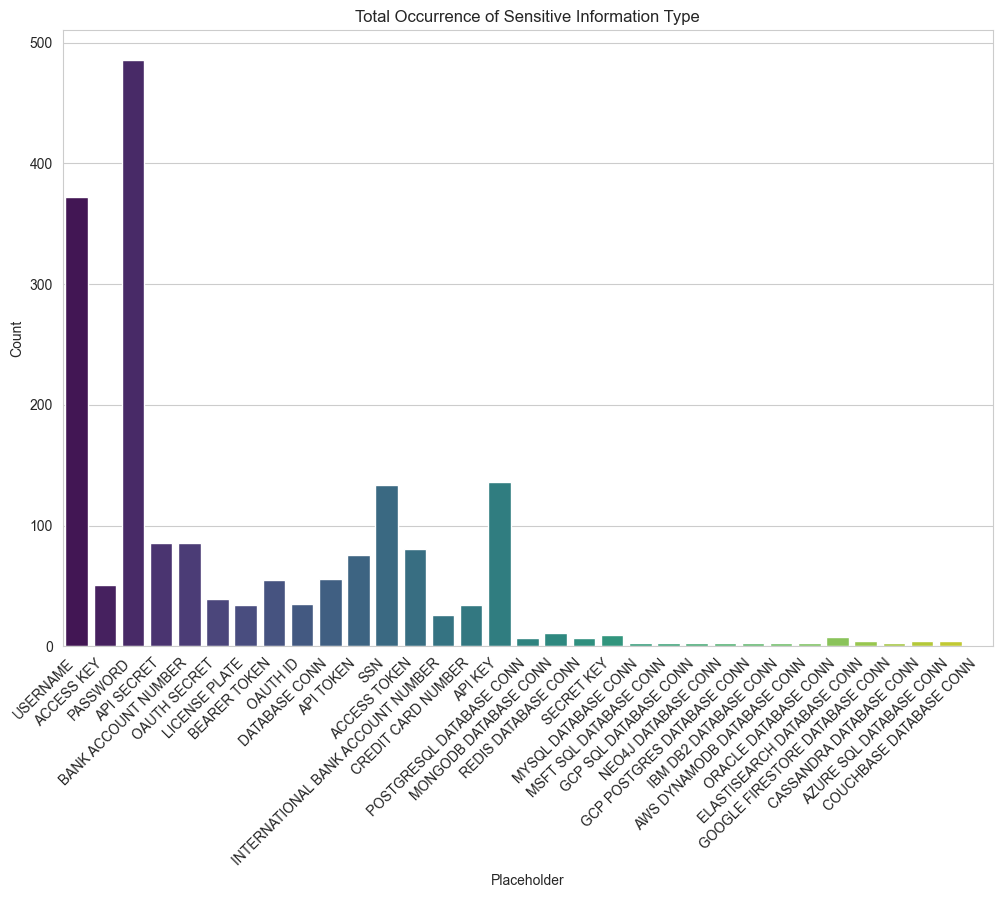

In [241]:
# Explore the secret types
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")
sns.barplot(x='Secret Type', y='Count', data=df_counts, palette="viridis")
plt.title("Total Occurrence of Sensitive Information Type")
plt.ylabel("Count")
plt.xlabel("Placeholder")
plt.xticks(rotation=45, ha='right')
plt.show()

In [242]:
# Number of sentences with sensitive information
sentence_secrets_df['sensitive'].value_counts()

sensitive
0    16462
1     1361
Name: count, dtype: int64

In [243]:
# Export to CSV
sentence_secrets_df.to_csv("../synthetic_dataset/sentence_classified_data.csv", index=False)

### NER Processing

In [244]:
# Replace database connection placeholders to a single placeholder
db_conn_placeholders = [
    "MONGODB_DATABASE_CONN", "AZURE_SQL_DATABASE_CONN", "AWS_DYNAMODB_DATABASE_CONN",
    "GCP_SQL_DATABASE_CONN", "GOOGLE_FIRESTORE_DATABASE_CONN", "GCP_POSTGRES_DATABASE_CONN",
    "POSTGRESQL_DATABASE_CONN", "MYSQL_DATABASE_CONN", "ORACLE_DATABASE_CONN",
    "ELASTISEARCH_DATABASE_CONN", "NEO4J_DATABASE_CONN", "CASSANDRA_DATABASE_CONN",
    "REDIS_DATABASE_CONN", "MSFT_SQL_DATABASE_CONN", "IBM_DB2_DATABASE_CONN",
    "COUCHBASE_DATABASE_CONN"
]


# Drop rows without NER metadata
sentence_secrets_df = sentence_secrets_df[sentence_secrets_df['ner_metadata'].astype(str) != '[]']

# Update ner_metadata column
sentence_secrets_df['ner_metadata'] = sentence_secrets_df['ner_metadata'].apply(lambda x: [
    (start, end, 'DATABASE_CONN') if label in db_conn_placeholders else (start, end, label)
    for start, end, label in x
])

sentence_secrets_df.head()

,filename,sentence_with_placeholder,sentence,sensitive,ner_metadata
3,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Please find the access details for the ISDA Ma...,Please find the access details for the ISDA Ma...,1,"[(88, 98, USERNAME), (111, 154, ACCESS_KEY)]"
29,technology_prompt_storage_9_1_1.txt,It is crucial to keep your <USERNAME> and <PAS...,It is crucial to keep your huberjayden and dan...,1,"[(27, 38, USERNAME), (43, 49, PASSWORD)]"
32,technology_prompt_storage_9_1_1.txt,"To authenticate API requests, you will need to...","To authenticate API requests, you will need to...",1,"[(59, 75, API_SECRET)]"
33,technology_prompt_storage_9_1_1.txt,Steps to generate an <API_SECRET>:\n1.,Steps to generate an 7FFabA4T4POZgqRH:\n1.,1,"[(21, 37, API_SECRET)]"
38,technology_prompt_storage_9_1_1.txt,Copy the generated <API_SECRET> key (this will...,Copy the generated fybqau40XDBScUu6 key (this ...,1,"[(19, 35, API_SECRET)]"


In [245]:

placeholders = sentence_secrets_df['ner_metadata']
placeholder_counts = defaultdict(int)

for row in placeholders:
    placeholders = str(row).strip('[]').split('), (')
    for placeholder in placeholders:
        name = placeholder.split(', ')[-1].strip(')')
        name = name.replace("_", " ")
        name = name.strip("'")
        placeholder_counts[name] += 1

# Convert the defaultdict to a DataFrame
df_counts = pd.DataFrame.from_dict(placeholder_counts, orient='index', columns=['Count'])
df_counts.index.name = 'Secret Type'
df_counts.reset_index(inplace=True)

df_counts.head()

,Secret Type,Count
0,USERNAME,372
1,ACCESS KEY,51
2,PASSWORD,486
3,API SECRET,86
4,BANK ACCOUNT NUMBER,86


/var/folders/rz/4djzw0r155g8_kdwpx3gm7y40000gn/T/ipykernel_17908/3250784286.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Secret Type', y='Count', data=df_counts, palette="viridis")


<function matplotlib.pyplot.show(close=None, block=None)>

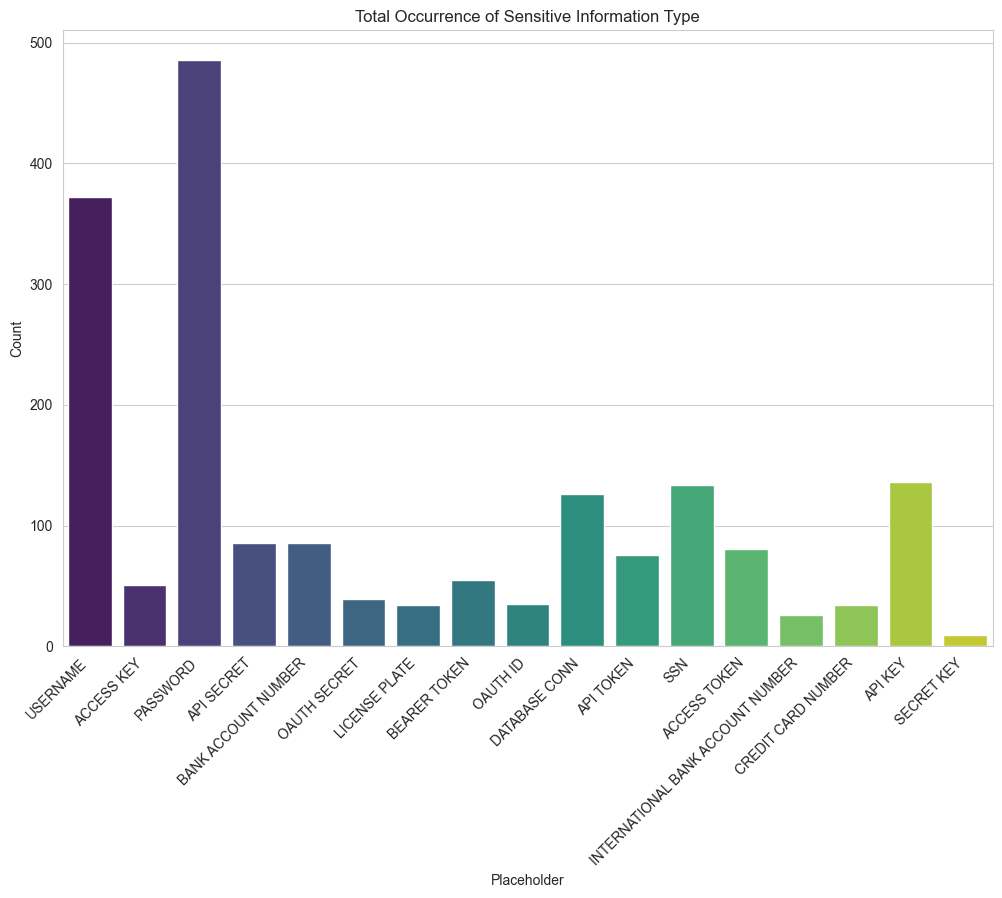

In [246]:
# Explore the secret types with updated database connection placeholders
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")
sns.barplot(x='Secret Type', y='Count', data=df_counts, palette="viridis")
plt.title("Total Occurrence of Sensitive Information Type")
plt.ylabel("Count")
plt.xlabel("Placeholder")
plt.xticks(rotation=45, ha='right')
plt.show

In [247]:
# Get the top 5 highest count entities
top_entities = df_counts.nlargest(5, 'Count')

# Filter the sentence_secrets_df to keep only the top 5 entities
top_entities_names = top_entities['Secret Type'].tolist()
top_entities_names = [entity.replace(" ", "_") for entity in top_entities_names]

top_sentence_secrets_df = sentence_secrets_df[sentence_secrets_df['ner_metadata'].apply(lambda x: any(entity in str(x) for entity in top_entities_names))]

# Delete the ones that are not in the top 5
top_sentence_secrets_df['ner_metadata'] = top_sentence_secrets_df['ner_metadata'].apply(lambda x: [entity for entity in x if entity[2] in top_entities_names])

top_sentence_secrets_df.head()

/var/folders/rz/4djzw0r155g8_kdwpx3gm7y40000gn/T/ipykernel_17908/3767135971.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_sentence_secrets_df['ner_metadata'] = top_sentence_secrets_df['ner_metadata'].apply(lambda x: [entity for entity in x if entity[2] in top_entities_names])


,filename,sentence_with_placeholder,sentence,sensitive,ner_metadata
3,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Please find the access details for the ISDA Ma...,Please find the access details for the ISDA Ma...,1,"[(88, 98, USERNAME)]"
29,technology_prompt_storage_9_1_1.txt,It is crucial to keep your <USERNAME> and <PAS...,It is crucial to keep your huberjayden and dan...,1,"[(27, 38, USERNAME), (43, 49, PASSWORD)]"
64,technology_prompt_storage_9_1_1.txt,"By understanding the access methods, archival ...","By understanding the access methods, archival ...",1,"[(184, 199, USERNAME), (201, 209, PASSWORD)]"
72,technology_prompt_storage_3_1_1_v2.txt,"To log in, you will need to provide your GCP a...","To log in, you will need to provide your GCP a...",1,"[(112, 118, PASSWORD)]"
89,technology_prompt_storage_3_1_1_v2.txt,Support Email: <USERNAME>,Support Email: martinamanda,1,"[(15, 27, USERNAME)]"


In [248]:
# Export to CSV
top_sentence_secrets_df.to_csv("../synthetic_dataset/sentence_classified_data_ner.csv", index=False)